# Proximity-ops digital twin — trajectory playback (Unity + ZeroMQ)
**Digital Twin — Test Bed Team.** This notebook is the "brain" of the twin:

1. loads the reference trajectory (debris-centred LVLH, 0.1 s steps),
2. maps it into the lab/table frame and decides the robot layout,
3. writes Unity-ready URDFs for the two ReBot B601-RS arms (debris arm + chaser arm on a linear rail),
4. solves inverse kinematics for every sample,
5. streams joint commands to Unity over ZeroMQ (Unity side uses NetMQ) and records what Unity reports back,
6. checks tracking error and the ≤ 30 cm threshold.

Run the cells top to bottom. Sections 1–5 need no Unity; section 6 needs Unity in Play mode.

In [1]:
# 0. Dependencies (run once)
%pip install -q numpy pandas scipy matplotlib pyzmq

Note: you may need to restart the kernel to use updated packages.


## 1. Configuration — edit the two paths
`RS_DIR` is the folder that contains `urdf/` and `meshes/` from the ReBot package
(`rebot_b601_rs_urdf/rebotarm_bringup/description/RS`).

In [5]:
from pathlib import Path
import json, time, re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
from scipy.optimize import least_squares

CSV_PATH = Path(r"trajectory_orbit_lvlh.csv")  # <-- edit
RS_DIR   = Path(r"../UnityProject/Assets/RS")  # <-- edit
SRC_URDF = RS_DIR / "urdf" / "ReBot_Arm_RS.urdf"

# ---- Test-bed layout (lab frame: right-handed, Z up, origin = centre of table top, metres) ----
TABLE_L, TABLE_W = 2.000, 0.740          # table top, X along the 2000 mm length
H        = 0.30                          # height of both satellite centres above the table
TCP      = 0.05                          # satellite centre sits 5 cm beyond the gripper tip, along the tool axis
SAT_SIZE = (0.10, 0.10)                  # (chaser, debris) cube edge for the Unity mock-ups

DEBRIS_CENTRE    = np.array([0.90, 0.00, H])   # debris is fixed here (origin of LVLH)
DEBRIS_BASE_POS  = np.array([0.90, -0.32, 0.0])
DEBRIS_BASE_YAW  = np.deg2rad(90)              # debris arm faces +Y and holds the debris over the centreline

RAIL_BASE_POS    = np.array([-0.95, 0.00, 0.0])  # start of the linear rail (chaser arm rides on it along +X)
RAIL_LENGTH      = 1.25
RAIL_CARRIAGE_H  = 0.02                          # carriage plate thickness: arm base sits this high on the rail
CHASER_STANDOFF  = 0.35                          # satellite centre is kept 0.35 m ahead of the chaser arm base (in X)

THRESHOLD = 0.30

## 2. Load and sanity-check the trajectory

6001 rows, t = 0.0 … 600.0 s, dt = 0.100 s
range: start 1.500 m, end 0.300 m, min 0.300 m
x ∈ [-0.181, 0.000], y ∈ [-1.500, -0.300], z ∈ [0.000, 0.000]
max |v_csv - v_fd| = 5.000001470148452e-09 m/s


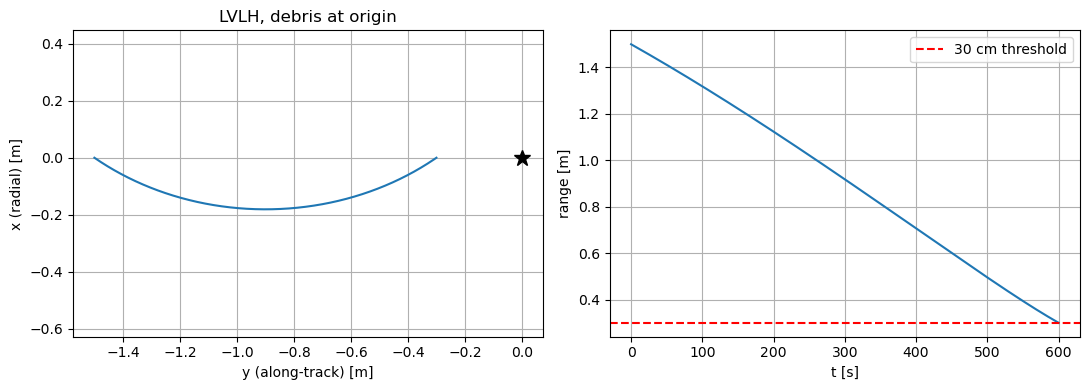

In [6]:
traj = pd.read_csv(CSV_PATH)
t   = traj.t_s.to_numpy()
r_l = traj[['x_m','y_m','z_m']].to_numpy()      # chaser position wrt debris, LVLH
v_l = traj[['vx_ms','vy_ms','vz_ms']].to_numpy()
rng = np.linalg.norm(r_l, axis=1)
print(f"{len(traj)} rows, t = {t[0]} … {t[-1]} s, dt = {np.diff(t).mean():.3f} s")
print(f"range: start {rng[0]:.3f} m, end {rng[-1]:.3f} m, min {rng.min():.3f} m")
print(f"x ∈ [{r_l[:,0].min():.3f}, {r_l[:,0].max():.3f}], y ∈ [{r_l[:,1].min():.3f}, {r_l[:,1].max():.3f}], z ∈ [{r_l[:,2].min():.3f}, {r_l[:,2].max():.3f}]")
# finite-difference check that the velocity columns are consistent with the positions
vfd = np.gradient(r_l, t, axis=0)
print("max |v_csv - v_fd| =", np.abs(vfd - v_l)[1:-1].max(), "m/s")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(r_l[:,1], r_l[:,0]); ax[0].plot(0, 0, 'k*', ms=12)
ax[0].set_xlabel('y (along-track) [m]'); ax[0].set_ylabel('x (radial) [m]'); ax[0].set_title('LVLH, debris at origin'); ax[0].axis('equal'); ax[0].grid()
ax[1].plot(t, rng); ax[1].axhline(THRESHOLD, color='r', ls='--', label='30 cm threshold')
ax[1].set_xlabel('t [s]'); ax[1].set_ylabel('range [m]'); ax[1].legend(); ax[1].grid()
plt.tight_layout()

## 3. Frames
| Frame | Convention | Use |
|---|---|---|
| **LVLH** (debris-centred) | x radial, y along-track, z orbit normal; right-handed | the CSV |
| **Lab** | right-handed, Z up, origin at centre of table top, X along the 2 m length | IK, everything in Python |
| **Unity** | left-handed, Y up | rendering only |

The trajectory is planar (z ≡ 0), so the orbital plane is laid flat on the table:
lab X = LVLH y (approach axis along the table), lab Y = −LVLH x, lab Z = LVLH z (det = +1, a proper rotation).
Chaser centre in the lab: **C(t) = D + R·r(t)**, with D the fixed debris centre.

Lab → Unity uses the same convention as Unity's URDF Importer / ROS-TCP-Connector: Unity (x, y, z) = (−Y, Z, X).

In [7]:
R_L2W = np.array([[0, 1, 0],
                  [-1, 0, 0],
                  [0, 0, 1.]])
assert np.isclose(np.linalg.det(R_L2W), 1)

C_ref = DEBRIS_CENTRE + r_l @ R_L2W.T            # chaser centre, lab frame
D_ref = np.tile(DEBRIS_CENTRE, (len(t), 1))

def lab_to_unity(p):  p = np.asarray(p); return np.stack([-p[...,1], p[...,2], p[...,0]], -1)
def unity_to_lab(u):  u = np.asarray(u); return np.stack([u[...,2], -u[...,0], u[...,1]], -1)
def yaw_lab_to_unity_deg(yaw): return -np.rad2deg(yaw)   # rotation about lab +Z == rotation about Unity +Y with opposite sign

print("chaser centre X range:", C_ref[:,0].min().round(3), "…", C_ref[:,0].max().round(3), " (table X ∈ ±1.0)")
print("chaser centre Y range:", C_ref[:,1].min().round(3), "…", C_ref[:,1].max().round(3), " (table Y ∈ ±0.37)")
assert np.all(np.abs(C_ref[:,0]) < TABLE_L/2) and np.all(np.abs(C_ref[:,1]) < TABLE_W/2)

chaser centre X range: -0.6 … 0.6  (table X ∈ ±1.0)
chaser centre Y range: 0.0 … 0.181  (table Y ∈ ±0.37)


## 4. Unity-ready URDFs
Two files are written next to `meshes/` in `RS_DIR`:
* `ReBot_Debris.urdf` — the arm as delivered (mesh paths rewritten so Unity's importer finds them),
* `ReBot_Chaser_Rail.urdf` — the same arm on a prismatic **rail_joint** (1.25 m stroke along +X).

The ReBot reaches ~0.6–0.7 m and can only hold a level satellite between ~0.25 and 0.7 m from its base,
so a single fixed arm cannot cover the 1.2 m of closing motion; the rail supplies the along-track motion
and the arm handles the radial offset and height (this is the "linear rail / extra DoF" option in the brief).

In [8]:
src = SRC_URDF.read_text(encoding="utf-8")
# Unity's URDF Importer resolves package:// relative to the folder containing the .urdf,
# so the URDFs go in RS_DIR and meshes are referenced as package://meshes/...
fixed = src.replace("package://rebotarm_bringup/description/RS/", "package://")

debris_urdf = re.sub(r'<robot\s+name="[^"]*"', '<robot\n  name="ReBot_Debris"', fixed, count=1)
(RS_DIR / "ReBot_Debris.urdf").write_text(debris_urdf, encoding="utf-8")

rail_xml = f'''
  <material name="rail_grey"><color rgba="0.55 0.57 0.60 1" /></material>
  <link name="rail_base">
    <inertial><origin xyz="{RAIL_LENGTH/2} 0 0.01" rpy="0 0 0"/><mass value="5"/>
      <inertia ixx="0.01" ixy="0" ixz="0" iyy="0.7" iyz="0" izz="0.7"/></inertial>
    <visual><origin xyz="{RAIL_LENGTH/2+0.05} 0 -0.005" rpy="0 0 0"/>
      <geometry><box size="{RAIL_LENGTH+0.2} 0.08 0.01"/></geometry><material name="rail_grey"/></visual>
  </link>
  <link name="rail_carriage">
    <inertial><origin xyz="0 0 {RAIL_CARRIAGE_H/2}" rpy="0 0 0"/><mass value="0.5"/>
      <inertia ixx="0.001" ixy="0" ixz="0" iyy="0.001" iyz="0" izz="0.001"/></inertial>
    <visual><origin xyz="0 0 {RAIL_CARRIAGE_H/2}" rpy="0 0 0"/>
      <geometry><box size="0.16 0.14 {RAIL_CARRIAGE_H}"/></geometry><material name="rail_grey"/></visual>
  </link>
  <joint name="rail_joint" type="prismatic">
    <origin xyz="0 0 0" rpy="0 0 0"/><parent link="rail_base"/><child link="rail_carriage"/>
    <axis xyz="1 0 0"/><limit lower="0" upper="{RAIL_LENGTH}" effort="200" velocity="0.5"/>
  </joint>
  <joint name="rail_to_arm" type="fixed">
    <origin xyz="0 0 {RAIL_CARRIAGE_H}" rpy="0 0 0"/><parent link="rail_carriage"/><child link="base_link"/>
  </joint>
'''
chaser_urdf = re.sub(r'<robot\s+name="[^"]*"\s*>', '<robot\n  name="ReBot_Chaser_Rail">' + rail_xml, fixed, count=1)
(RS_DIR / "ReBot_Chaser_Rail.urdf").write_text(chaser_urdf, encoding="utf-8")

# sanity: every mesh referenced must exist on disk
missing = [m for m in set(re.findall(r'package://([^"]+)', fixed)) if not (RS_DIR / m).exists()]
print("written:", RS_DIR / "ReBot_Debris.urdf", "and", RS_DIR / "ReBot_Chaser_Rail.urdf")
print("missing meshes:", missing or "none")

written: C:\Users\Tanishq\Desktop\CDE2605R\rebot_b601_rs_urdf\rebot_b601_rs_urdf\rebotarm_bringup\description\RS\ReBot_Debris.urdf and C:\Users\Tanishq\Desktop\CDE2605R\rebot_b601_rs_urdf\rebot_b601_rs_urdf\rebotarm_bringup\description\RS\ReBot_Chaser_Rail.urdf
missing meshes: none


## 5. Kinematics straight from the URDF, then IK for every sample
Forward kinematics is built by chaining the URDF joint origins and axes (no ROS needed).
IK: rail position is set analytically (keeps the satellite `CHASER_STANDOFF` ahead of the arm base),
then a bounded least-squares solve gives the 6 arm joints for the satellite **position and attitude**
(the chaser is held LVLH-fixed with its +X face pointing at the debris; the debris arm holds one static pose).

In [9]:
def rpy2R(r, p, y):
    cr, sr, cp, sp, cy, sy = np.cos(r), np.sin(r), np.cos(p), np.sin(p), np.cos(y), np.sin(y)
    return np.array([[cy*cp, cy*sp*sr - sy*cr, cy*sp*cr + sy*sr],
                     [sy*cp, sy*sp*sr + cy*cr, sy*sp*cr - cy*sr],
                     [-sp,   cp*sr,            cp*cr]])
def axang(a, q):
    a = a / np.linalg.norm(a); K = np.array([[0,-a[2],a[1]],[a[2],0,-a[0]],[-a[1],a[0],0]])
    return np.eye(3) + np.sin(q)*K + (1-np.cos(q))*K@K
def Rz(a): c, s = np.cos(a), np.sin(a); return np.array([[c,-s,0],[s,c,0],[0,0,1.]])
def hom(R=np.eye(3), p=np.zeros(3)): T = np.eye(4); T[:3,:3] = R; T[:3,3] = p; return T

class Arm:
    def __init__(self, urdf, base="base_link", tip="gripper_end"):
        J = {j.find('child').get('link'): j for j in ET.parse(urdf).getroot().findall('joint')}
        chain, l = [], tip
        while l != base: j = J[l]; chain.append(j); l = j.find('parent').get('link')
        self.joints = []
        for j in reversed(chain):
            o = j.find('origin'); ax = j.find('axis'); lim = j.find('limit')
            self.joints.append(dict(
                name=j.get('name'), type=j.get('type'),
                T=hom(rpy2R(*map(float, o.get('rpy').split())), np.array(list(map(float, o.get('xyz').split())))),
                axis=np.array(list(map(float, ax.get('xyz').split()))) if ax is not None else None,
                lim=(float(lim.get('lower')), float(lim.get('upper'))) if lim is not None else None))
        act = [j for j in self.joints if j['type'] != 'fixed']
        self.names = [j['name'] for j in act]
        self.lo = np.array([j['lim'][0] for j in act]); self.hi = np.array([j['lim'][1] for j in act])
    def fk(self, q):
        T, i = np.eye(4), 0
        for j in self.joints:
            T = T @ j['T']
            if j['type'] != 'fixed': T = T @ hom(axang(j['axis'], q[i])); i += 1
        return T
    def ik(self, T_goal, q0, w_rot=0.05, w_reg=1e-3):
        p, R = T_goal[:3,3], T_goal[:3,:3]
        def res(q):
            T = self.fk(q)
            return np.r_[T[:3,3]-p, w_rot*(T[:3,0]-R[:,0]), w_rot*(T[:3,2]-R[:,2]), w_reg*(q-q0)]
        q0 = np.clip(q0, self.lo+1e-6, self.hi-1e-6)
        sol = least_squares(res, q0, bounds=(self.lo, self.hi), xtol=1e-12, ftol=1e-12)
        T = self.fk(sol.x)
        return sol.x, np.linalg.norm(T[:3,3]-p), np.degrees(np.arccos(np.clip((np.trace(T[:3,:3].T@R)-1)/2, -1, 1)))

arm = Arm(SRC_URDF)
print("arm joints:", arm.names)
print("limits [rad]:", list(zip(arm.lo, arm.hi)))
print("home tool pose (base frame):\n", arm.fk(np.zeros(6)).round(4))

arm joints: ['joint1', 'joint2', 'joint3', 'joint4', 'joint5', 'joint6']
limits [rad]: [(np.float64(-2.8), np.float64(2.8)), (np.float64(0.0), np.float64(3.14)), (np.float64(0.0), np.float64(3.14)), (np.float64(-1.57), np.float64(1.57)), (np.float64(-1.57), np.float64(1.57)), (np.float64(-3.14), np.float64(3.14))]
home tool pose (base frame):
 [[ 1.      0.     -0.      0.3017]
 [ 0.      1.      0.      0.    ]
 [-0.     -0.      1.      0.2177]
 [ 0.      0.      0.      1.    ]]


In [11]:
# Desired satellite attitudes (lab frame). Tool frame of gripper_end: +X out of the gripper, +Z up at home.
R_CHASER = np.eye(3)                 # chaser +X face points along +X (toward the debris), Z up
R_DEBRIS = Rz(DEBRIS_BASE_YAW)       # debris simply held level by an arm facing +Y
T_tcp = hom(p=np.array([TCP, 0, 0])) # gripper_end -> satellite centre

def gripper_goal(centre, R_sat):     # satellite-centre pose -> gripper_end pose (lab)
    return hom(R_sat, centre) @ np.linalg.inv(T_tcp)

# --- debris arm: one static pose ---
T_deb_base = hom(Rz(DEBRIS_BASE_YAW), DEBRIS_BASE_POS)
seeds = [np.array([0, .8, 1.2, .4, 0, 0]), np.array([0, 1.5, 2.0, .5, 0, 0]), np.array([0, 1.0, 1.6, .6, 0, 0])]
q_deb, e_deb, a_deb = min((arm.ik(np.linalg.inv(T_deb_base) @ gripper_goal(DEBRIS_CENTRE, R_DEBRIS), s) for s in seeds),
                          key=lambda s: s[1] + 0.02*np.radians(s[2]))
print(f"debris arm: q = {np.round(q_deb,4)}  pos err {e_deb*1e3:.3f} mm, att err {a_deb:.3f}°")

# --- chaser: rail (analytic) + arm (IK) for every sample ---
N = len(t)
rail = C_ref[:,0] - CHASER_STANDOFF - RAIL_BASE_POS[0]
assert rail.min() >= 0 and rail.max() <= RAIL_LENGTH, (rail.min(), rail.max())
Q_ch = np.zeros((N, 6)); E_ch = np.zeros(N); A_ch = np.zeros(N)
q = np.array([0, .8, 1.2, .4, 0, 0])
t0 = time.time()
for k in range(N):
    T_base = hom(p=RAIL_BASE_POS + [rail[k], 0, RAIL_CARRIAGE_H])
    goal = np.linalg.inv(T_base) @ gripper_goal(C_ref[k], R_CHASER)
    q, E_ch[k], A_ch[k] = arm.ik(goal, q)
    if k == 0 and E_ch[0] > 1e-4:     # first point: try other seeds
        q, E_ch[0], A_ch[0] = min((arm.ik(goal, s) for s in seeds), key=lambda s: s[1])
    Q_ch[k] = q
print(f"IK for {N} samples in {time.time()-t0:.1f} s")
print(f"chaser: max pos err {E_ch.max()*1e3:.3f} mm, max att err {A_ch.max():.3f}°")
qd = np.abs(np.diff(Q_ch, axis=0)).max(0) / np.diff(t).min()
print("max joint speed [rad/s]:", qd.round(4), " rail speed max [m/s]:", np.abs(np.diff(rail)/np.diff(t)).max().round(4))
margin = np.minimum(Q_ch - arm.lo, arm.hi - Q_ch).min(0)
print("min distance to joint limits [rad]:", margin.round(3))

debris arm: q = [-0.      0.0732  0.3779 -0.305  -0.     -0.    ]  pos err 0.010 mm, att err 0.012°
IK for 6001 samples in 22.9 s
chaser: max pos err 0.009 mm, max att err 0.012°
max joint speed [rad/s]: [0.0122 0.0044 0.0028 0.004  0.0122 0.    ]  rail speed max [m/s]: 0.0021
min distance to joint limits [rad]: [1.726 0.193 0.267 1.006 0.496 3.14 ]


max |sep_fk - range_ref| = 0.0072964100792383135 mm
saved joint_trajectory.csv


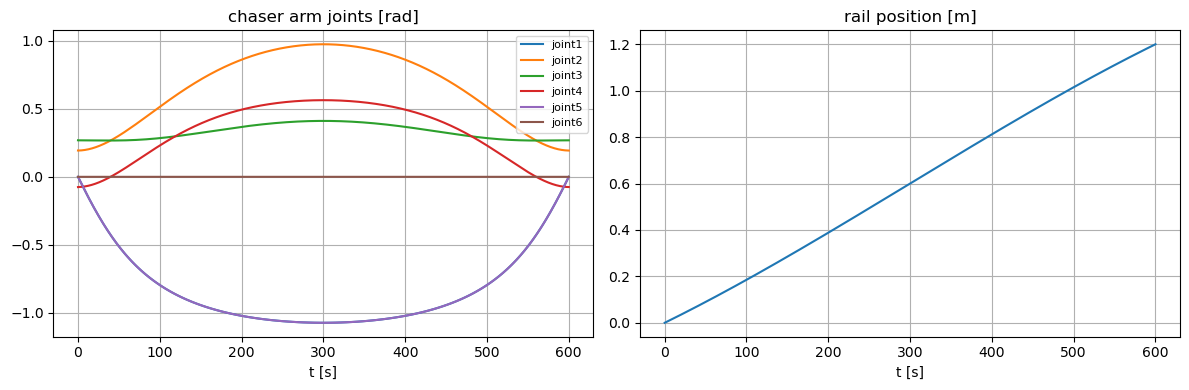

In [12]:
# Independent check: FK of the solved joints reproduces the reference separation
def chaser_centre_fk(rail_k, qk):
    return (hom(p=RAIL_BASE_POS + [rail_k, 0, RAIL_CARRIAGE_H]) @ arm.fk(qk) @ T_tcp)[:3,3]
deb_fk = (T_deb_base @ arm.fk(q_deb) @ T_tcp)[:3,3]
C_fk = np.array([chaser_centre_fk(rail[k], Q_ch[k]) for k in range(0, N, 10)])
sep_fk = np.linalg.norm(C_fk - deb_fk, axis=1)
print("max |sep_fk - range_ref| =", np.abs(sep_fk - rng[::10]).max()*1e3, "mm")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(t, Q_ch); ax[0].legend(arm.names, fontsize=8); ax[0].set_title('chaser arm joints [rad]'); ax[0].set_xlabel('t [s]'); ax[0].grid()
ax[1].plot(t, rail); ax[1].set_title('rail position [m]'); ax[1].set_xlabel('t [s]'); ax[1].grid()
plt.tight_layout()

out = pd.DataFrame({'t_s': t, 'rail_joint': rail, **{f'chaser_{n}': Q_ch[:,i] for i, n in enumerate(arm.names)},
                    **{f'debris_{n}': np.full(N, q_deb[i]) for i, n in enumerate(arm.names)},
                    'ref_sep_m': rng})
out.to_csv("joint_trajectory.csv", index=False); print("saved joint_trajectory.csv")

## 5b. Numbers to type into Unity
Place the two imported robots with these **Transform** values (the script in Unity checks them and reports back).

In [13]:
for name, pos, yaw in [("ReBot_Chaser_Rail", RAIL_BASE_POS, 0.0), ("ReBot_Debris", DEBRIS_BASE_POS, DEBRIS_BASE_YAW)]:
    u = lab_to_unity(pos)
    print(f"{name:18s} Position ({u[0]:.3f}, {u[1]:.3f}, {u[2]:.3f})   Rotation (0, {yaw_lab_to_unity_deg(yaw):.1f}, 0)")
print(f"\nTestbedTwin inspector: Tcp = {TCP}, Chaser Size = {SAT_SIZE[0]}, Debris Size = {SAT_SIZE[1]}, "
      f"Table = {TABLE_W} x {TABLE_L}")

ReBot_Chaser_Rail  Position (-0.000, 0.000, -0.950)   Rotation (0, -0.0, 0)
ReBot_Debris       Position (0.320, 0.000, 0.900)   Rotation (0, -90.0, 0)

TestbedTwin inspector: Tcp = 0.05, Chaser Size = 0.1, Debris Size = 0.1, Table = 0.74 x 2.0


## 6. ZeroMQ link to Unity
* Python **binds** both sockets; Unity **connects** (so you can stop/start Play mode freely).
* `tcp://*:5556` PUB, topic `cmd` → joint targets (radians, metres) + reference positions.
* `tcp://*:5557` SUB, topic `state` ← what Unity actually did (satellite centres in lab frame, measured joints).

Press **Play** in Unity, then run the cells below.

In [35]:
import zmq

class TwinLink:
    def __init__(self, cmd_port=5556, state_port=5557):
        self.ctx = zmq.Context.instance()
        self.pub = self.ctx.socket(zmq.PUB); self.pub.setsockopt(zmq.LINGER, 0); self.pub.bind(f"tcp://*:{cmd_port}")
        self.sub = self.ctx.socket(zmq.SUB); self.sub.setsockopt(zmq.LINGER, 0)
        self.sub.setsockopt_string(zmq.SUBSCRIBE, "state"); self.sub.bind(f"tcp://*:{state_port}")
        self.states = []
    def send(self, seq, tk, rail_k, q_c, q_d, ref_c, ref_d):
        msg = dict(type="cmd", seq=int(seq), t=float(tk),
                   chaser=[float(rail_k)] + [float(x) for x in q_c], debris=[float(x) for x in q_d],
                   ref_c=[float(x) for x in ref_c], ref_d=[float(x) for x in ref_d])
        self.pub.send_multipart([b"cmd", json.dumps(msg).encode()])
    def poll(self):
        n = 0
        while self.sub.poll(0):
            _, payload = self.sub.recv_multipart(); s = json.loads(payload); s["rx"] = time.time()
            self.states.append(s); n += 1
        return n
    def wait_for_unity(self, timeout=60):
        t_end = time.time() + timeout
        while time.time() < t_end:
            self.send(-1, 0.0, rail[0], Q_ch[0], q_deb, C_ref[0], D_ref[0])   # hold the start pose
            if self.poll(): return self.states[-1]
            time.sleep(0.1)
        raise TimeoutError("no state from Unity — is it in Play mode and is TestbedTwin enabled?")
    def close(self): self.pub.close(); self.sub.close()

try: link.close()
except NameError: pass
link = TwinLink()
hello = link.wait_for_unity()
print("Unity connected. Reported bases (lab):", hello.get("chaser_base"), hello.get("debris_base"))
for nm, rep, exp in [("chaser", hello.get("chaser_base"), RAIL_BASE_POS), ("debris", hello.get("debris_base"), DEBRIS_BASE_POS)]:
    if rep is not None and np.linalg.norm(np.array(rep) - exp) > 0.005:
        print(f"⚠ {nm} robot is not where the notebook expects ({rep} vs {exp}) — fix its Transform in Unity")

Unity connected. Reported bases (lab): [-0.949999988079071, 0.0, 0.0] [0.8999999761581421, -0.3199999928474426, 9.313225746154785e-09]


### 6a. Joint-convention check (do this once after importing)
Holds the start pose, then two test poses; compares the satellite position Unity measures with Python FK.
Errors of a few mm mean the joint signs/axes match; errors of centimetres mean a joint is mirrored.

In [20]:
def hold(rail_k, q_c, seconds=3.0):
    t_end = time.time() + seconds
    while time.time() < t_end:
        link.send(-2, 0, rail_k, q_c, q_deb, chaser_centre_fk(rail_k, q_c), deb_fk); link.poll(); time.sleep(0.05)
    s = link.states[-1]
    return np.array(s["chaser_c"]), np.array(s["debris_c"])

tests = [(rail[0], Q_ch[0]), (0.4, Q_ch[0] + np.array([0.3, 0.2, 0.3, 0.2, 0.3, 0.5])), (0.8, Q_ch[-1])]
for rk, qk in tests:
    qk = np.clip(qk, arm.lo, arm.hi)
    c_u, d_u = hold(rk, qk)
    print(f"rail {rk:.2f}: chaser err {np.linalg.norm(c_u - chaser_centre_fk(rk, qk))*1e3:6.1f} mm | "
          f"debris err {np.linalg.norm(d_u - deb_fk)*1e3:6.1f} mm")

rail 0.00: chaser err    0.0 mm | debris err    0.1 mm
rail 0.40: chaser err    0.1 mm | debris err    0.1 mm
rail 0.80: chaser err    0.2 mm | debris err    0.1 mm


### 6b. Play the trajectory
`SPEED = 10` plays the 600 s approach in 60 s. Every 0.1 s sample is sent; Unity reports at ~30 Hz.

In [36]:
SPEED = 10.0
link.states.clear()
hold(rail[0], Q_ch[0], 2.0)                    # settle at the start pose
link.states.clear()
t_wall0 = time.time()
for k in range(N):
    link.send(k, t[k], rail[k], Q_ch[k], q_deb, C_ref[k], D_ref[k])
    link.poll()
    sleep = t_wall0 + t[k]/SPEED - time.time()
    if sleep > 0: time.sleep(sleep)
hold_end = time.time() + 2.0                   # keep sending the final pose while the drives settle
while time.time() < hold_end:
    link.send(N-1, t[-1], rail[-1], Q_ch[-1], q_deb, C_ref[-1], D_ref[-1]); link.poll(); time.sleep(0.05)
print(f"streamed {N} samples in {time.time()-t_wall0:.1f} s, received {len(link.states)} state messages")

streamed 6001 samples in 62.0 s, received 873 state messages


## 7. Did the twin follow the trajectory?

tracking error (Unity vs reference): mean 2.82 mm, max 3.57 mm
final separation: 30.01 cm (reference 30.00 cm)
threshold ≤ 30 cm reached at t = 600.0 s


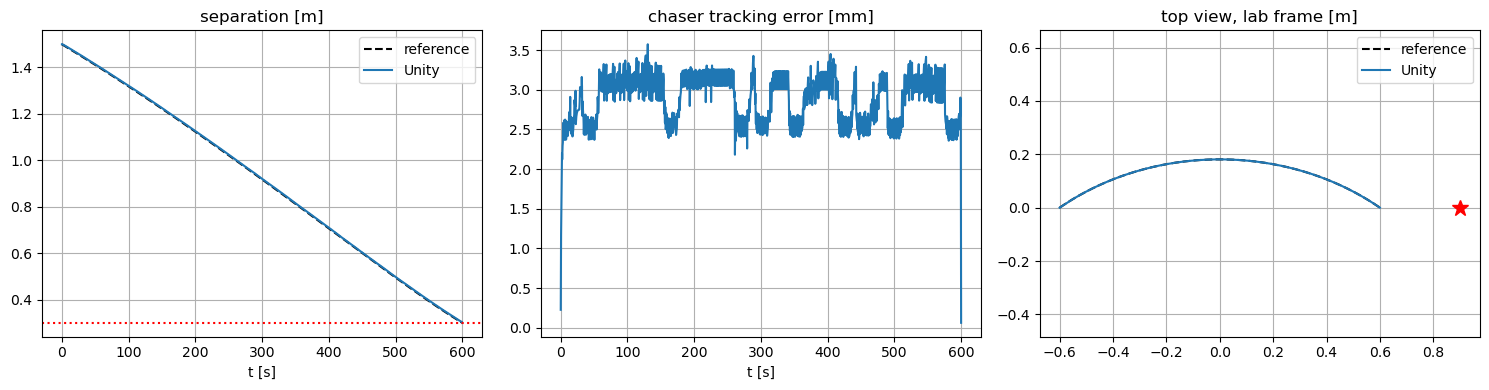

In [30]:
S = pd.DataFrame([s for s in link.states if s.get("seq", -1) >= 0])
S = S.drop_duplicates("seq", keep="last").sort_values("seq")
k = S.seq.to_numpy()
c_meas = np.vstack(S.chaser_c); d_meas = np.vstack(S.debris_c)
sep_meas = np.linalg.norm(c_meas - d_meas, axis=1)
err = np.linalg.norm(c_meas - C_ref[k], axis=1)
print(f"tracking error (Unity vs reference): mean {err.mean()*1e3:.2f} mm, max {err.max()*1e3:.2f} mm")
print(f"final separation: {sep_meas[-1]*100:.2f} cm (reference {rng[-1]*100:.2f} cm)")
TOL = 0.002   # the reference ends exactly on 30.0 cm, so allow 2 mm of drive/IK error
hit = np.where(sep_meas <= THRESHOLD + TOL)[0]
print("threshold ≤ 30 cm reached at t =", f"{t[k[hit[0]]]:.1f} s" if len(hit) else "never")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(t, rng, 'k--', label='reference'); ax[0].plot(t[k], sep_meas, label='Unity'); ax[0].axhline(THRESHOLD, color='r', ls=':')
ax[0].set_title('separation [m]'); ax[0].legend(); ax[0].grid()
ax[1].plot(t[k], err*1e3); ax[1].set_title('chaser tracking error [mm]'); ax[1].grid()
ax[2].plot(C_ref[:,0], C_ref[:,1], 'k--', label='reference'); ax[2].plot(c_meas[:,0], c_meas[:,1], label='Unity')
ax[2].plot(*DEBRIS_CENTRE[:2], 'r*', ms=12); ax[2].set_title('top view, lab frame [m]'); ax[2].axis('equal'); ax[2].legend(); ax[2].grid()
for a in ax[:2]: a.set_xlabel('t [s]')
plt.tight_layout()
S.to_csv("unity_run_log.csv", index=False)

In [37]:
link.close()   # release the ports (re-run section 6 to reconnect)